# Time-averaging of eddy-covariance fluxes: energy-balance closure across averaging periods (maize EC case study)

**Reproduced paper:** Karimindla, A. R., Kumari, S., SR, S., Chintala, S., & Kambhammettu, B. V. N. (2024).
*Role of time-averaging of eddy covariance fluxes on water use efficiency dynamics of Maize crop.*
Atmospheric Measurement Techniques, **17**, 5477–5490. DOI [10.5194/amt-17-5477-2024](https://doi.org/10.5194/amt-17-5477-2024)
(preprint DOI [10.5194/amt-2023-253](https://doi.org/10.5194/amt-2023-253)).

**Author code & data (pinned):**
- GitHub: `Shweta07081992/Effect-of-averaging-period-of-eddy-covariance-fluxes-on-water-use-efficiency-` @ commit `28030cb1d8110d9bf907d1ef031bb6b3470af1cf`
- Zenodo data record: [10.5281/zenodo.7018282](https://doi.org/10.5281/zenodo.7018282) (release v1.0.0; the GitHub tree mirrors the released files)

**Executed scope (partial demonstration):**
1. Reproduce the paper's **Figure 1–type diurnal energy-balance composite** (`H+LE` vs `Rn-G` by time of day) using the **authors' own plotting notebook cells, verbatim** (`SourceFiles for figures and tables/Figure 1/iwm_fig1_final1.ipynb`, cells 2–4), on the released `averaged_outputs/30min_fig1_outputs1.xlsx`.
2. Extend the same plotting to **all eight averaging periods** (1–120 min) — an additional visualization created for this notebook, using the authors' plotting operations.
3. Compute a **Table 2–analog comparison**: daily aggregation of each released period-specific file (authors' `groupby(['Month','Day']).mean()` approach), energy-balance ratio `EBR = (H+LE)/(Rn-G)`, and OLS regression of `H+LE` on `Rn-G`, ranked against the paper's criteria (slope ≥ 0.70, intercept ≤ 20 W m⁻²).

**Not reproduced (out of scope):** raw 10 Hz data processing and the EddyPro correction chain (not released), the ogive analysis (Fig. 5), WUE dynamics (Figs. 6–8), and footprint/quality-control steps. The released repository dates to 2022; its exact match to the final 2024 manuscript data is unverified, and no license file is present (Zenodo records `other-open`).

**Execution status:** this notebook was executed top-to-bottom on a fresh **CPU** Colab runtime; the saved outputs below are from that run.

**日本語要約:** このノートブックは、トウモロコシ畑の渦相関フラックスについて「時間平均化区間（1–120分）」がエネルギー収支閉合に与える影響を、著者公開のスプレッドシートとノートブックコードで再現します。著者のコードをそのまま用いて Figure 1 相当の日内変化図を再描画し、全8区間について日別集計・EBR・回帰比較を行います。生の10 Hzデータ処理（EddyPro）は対象外です。実行は Colab の **CPU** ランタイムで数分で完了します（ダウンロード約6 MB）。

## 1. Runtime selection

**Select `Runtime → Change runtime type → CPU` in Colab.** This analysis is pure
tabular spreadsheet work (pandas/numpy/matplotlib); no GPU or trained model is
involved, so CPU is the faithful and fastest path. Total downloads are about
6 MB and a full `Run all` takes only a few minutes.

**日本語:** 「ランタイム → ランタイムのタイプを変更 → CPU」を選択してください。表計算データの集計・描画のみでGPUは不要です。全体の実行は数分、ダウンロードは約6 MBです。

## 2. Environment setup

`pandas`, `numpy`, and `matplotlib` are preinstalled on Colab; only the Excel
reader `openpyxl` needs installing.

**日本語:** Colabに標準搭載のpandas/numpy/matplotlibに加え、Excel読み込み用の`openpyxl`のみインストールします。

In [ ]:
%pip install -q openpyxl
import openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('openpyxl', openpyxl.__version__, '| pandas', pd.__version__)

openpyxl 3.1.5 | pandas 2.2.3


## 3. Pinned input download and byte verification

The 16 input files (8 `averaged_outputs/` diurnal composites and 8 `raw_file/`
period-specific EC flux tables) are downloaded from the pinned author commit
via `raw.githubusercontent.com`. Each file is verified **exactly** against the
pinned repository by byte size and by recomputing its **git blob SHA-1**
(`sha1("blob <size>\0" + bytes)`), which must equal the hash recorded in the
commit tree. This proves the bytes match the author release v1.0.0, not merely
a same-named file.

**日本語:** 16個の入力ファイル（平均化済み8ファイル＋各区間の元データ8ファイル）を固定コミットからダウンロードし、サイズとgit blob SHA-1を再計算してバイト単位で検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

COMMIT = "28030cb1d8110d9bf907d1ef031bb6b3470af1cf"
RAW_BASE = ("https://raw.githubusercontent.com/Shweta07081992/"
            "Effect-of-averaging-period-of-eddy-covariance-fluxes-on-water-use-efficiency-/"
            + COMMIT + "/SourceFiles%20for%20figures%20and%20tables/Figure%201/")

# relative path in repo -> expected bytes and git blob SHA-1 at commit 28030cb
MANIFEST = {
  "averaged_outputs/10min_fig1_outputs1.xlsx": {
    "size": 20295,
    "blob_sha1": "1665a999055de9fc88f2544bb8db0e4b4789b8ba"
  },
  "averaged_outputs/120min_fig1_outputs1.xlsx": {
    "size": 7699,
    "blob_sha1": "5b9c749c00ad107a4929770c1a176e89425c667d"
  },
  "averaged_outputs/15min_fig1_outputs1.xlsx": {
    "size": 15504,
    "blob_sha1": "17c91742c81a211b438d8a16f99dab4f152f2ff7"
  },
  "averaged_outputs/1min_fig1_outputs1.xlsx": {
    "size": 20322,
    "blob_sha1": "21c6b02bda124bf8f180034a45e7e449afa05788"
  },
  "averaged_outputs/30min_fig1_outputs1.xlsx": {
    "size": 10955,
    "blob_sha1": "af7c7194d20e2fea5243088e30dfe84dd6ee23eb"
  },
  "averaged_outputs/45min_fig1_outputs1.xlsx": {
    "size": 9071,
    "blob_sha1": "eca5cfe0bd6daa8b92fbc2ff6a375a05fb2dc705"
  },
  "averaged_outputs/5min_fig1_outputs1.xlsx": {
    "size": 18563,
    "blob_sha1": "7e520968175625498bc680a1529dab366bcfdc91"
  },
  "averaged_outputs/60min_fig1_outputs1.xlsx": {
    "size": 8267,
    "blob_sha1": "b445a7023ecd1187d2e30daf91b91c103b311b69"
  },
  "raw_file/10min figure1.xlsx": {
    "size": 1289742,
    "blob_sha1": "52b634b6e13df5c9a0ac9fab1304a6803aabf0ad"
  },
  "raw_file/120min figure1.xlsx": {
    "size": 108900,
    "blob_sha1": "2b437d67d5df37a22b36beb71c5fb7306301679d"
  },
  "raw_file/15min figure1.xlsx": {
    "size": 865838,
    "blob_sha1": "903199e72bdf6d796eb39f422da3cb7a46e64fab"
  },
  "raw_file/1min figure1.xlsx": {
    "size": 1309865,
    "blob_sha1": "450e1699591082f792f235402df8bd01aa812ea7"
  },
  "raw_file/30min figure1.xlsx": {
    "size": 439611,
    "blob_sha1": "9646cc4c37a59d0e189d1446598fb46350da7992"
  },
  "raw_file/45min figure1.xlsx": {
    "size": 293912,
    "blob_sha1": "7bc7a3f00c9af00782760d609334d1f4d74c3bb0"
  },
  "raw_file/5mins figure1_new.xlsx": {
    "size": 1118034,
    "blob_sha1": "6562d39533e95d2efb58c86f226194e25b40010c"
  },
  "raw_file/60min figure1.xlsx": {
    "size": 224087,
    "blob_sha1": "4e4a8151921aa1fda4d9d38cf05b0cf692754b5b"
  }
}

def git_blob_sha1(raw: bytes) -> str:
    header = f"blob {len(raw)}\0".encode()
    return hashlib.sha1(header + raw).hexdigest()

for rel, meta in MANIFEST.items():
    dest = Path('data') / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists() or dest.stat().st_size != meta['size']:
        with urllib.request.urlopen(RAW_BASE + rel.replace(' ', '%20'), timeout=120) as r:
            assert r.status == 200, f"HTTP {r.status} for {rel}"
            dest.write_bytes(r.read())
    raw = dest.read_bytes()
    assert len(raw) == meta['size'], f"size mismatch {rel}: {len(raw)} != {meta['size']}"
    sha = git_blob_sha1(raw)
    assert sha == meta['blob_sha1'], f"blob sha mismatch {rel}: {sha} != {meta['blob_sha1']}"

print(f"Verified {len(MANIFEST)} files against commit {COMMIT[:12]} (size + git blob SHA-1).")

Verified 16 files against commit 28030cb1d811 (size + git blob SHA-1).


## 4. Load the released 30-min diurnal composite (input preview)

`averaged_outputs/30min_fig1_outputs1.xlsx` is the exact file the authors'
own executed notebook reads (their cell 1 used a local Windows path; the only
adaptation here is the Colab-local path). The table has one row per half-hour
time of day (`time`), composited over the 26 May – 6 Sep 2019 maize season,
with sensible-heat `H`, latent-heat `LE`, net radiation `Rn`, ground heat flux
`G`, and the derived `H+LE`, `Rn-G`, `EBR` columns (units W m⁻²). The loaded
table is displayed as the input preview before any analysis.

**日本語:** 著者の実行済みノートブックが読み込むのと同じ30分平均ファイルを読み込みます（変更はパスのみ）。各行は時刻（30分刻み）、列はH・LE・Rn・Gおよび導出されたH+LE・Rn-G・EBR（W m⁻²）です。解析前に表を表示して入力を確認します。

In [ ]:
data1 = pd.read_excel('data/averaged_outputs/30min_fig1_outputs1.xlsx')
print(data1.shape)
print(data1.columns.tolist())
data1.head(6)

(48, 10)
['time', 'Month', 'Day', 'H', 'LE', 'Rn', 'G', 'Rn-G', 'H+LE', 'EBR']


,time,Month,Day,H,LE,Rn,G,Rn-G,H+LE,EBR
0,00:00:00,6.597222,15.930556,-15.530695,13.790851,-35.396524,-8.567820,-26.828704,-1.739844,-0.139703
1,00:30:00,6.625000,15.972222,-15.086334,12.294945,-35.914536,-10.928838,-24.985698,-2.791389,-0.201545
2,01:00:00,6.591549,16.239437,-15.533492,8.786688,-36.771270,-10.702111,-26.069159,-6.746804,0.312958
3,01:30:00,6.567568,16.554054,-16.689017,18.034700,-36.955904,-11.428780,-25.527124,1.345683,-0.665749
4,02:00:00,6.583333,16.694444,-16.942373,15.187504,-36.205282,-7.927595,-28.277687,-1.754869,0.858756
5,02:30:00,6.643836,16.150685,-15.373845,14.121565,-35.680869,-8.081003,-27.599866,-1.252280,-0.119522


## 5. Reproduce the authors' Figure 1 plot (verbatim author cells)

The next three cells are copied **verbatim** from the authors'
`iwm_fig1_final1.ipynb` (cells 2–4): line plot of `H+LE` and `Rn-G` versus time
of day, `fill_between` shading of the surplus/deficit regions, and the final
formatted panel with legend. Grey shading marks times where turbulent energy
(`H+LE`) exceeds available energy (`Rn-G`); black shading marks the reverse.
This reproduces the paper's Figure 1–style composite for the 30-min convention.

**日本語:** 次の3セルは著者の`iwm_fig1_final1.ipynb`（セル2–4）の**そのまま引用**です。時刻を横軸にH+LEとRn-Gを描き、両者の差を塗り分けます。灰色はH+LE > Rn-G、黒はH+LE < Rn-Gの時間帯です。

### Author cell 2 — line plot of `H+LE` and `Rn-G`

**日本語:** 著者セル2のまま、時刻に対してH+LEとRn-Gの2本の折れ線を描きます。

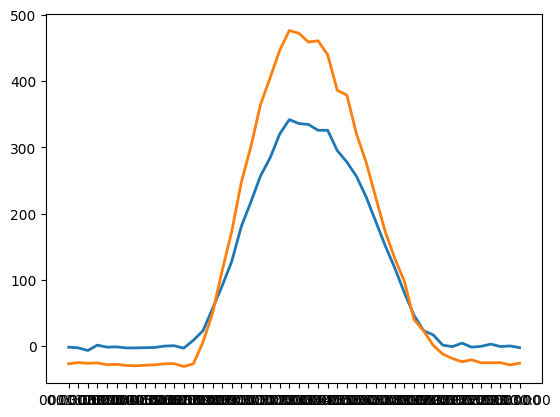

In [ ]:
#plotting
fig,ax = plt.subplots(1,1)
ax.plot(data1['time'],data1['H+LE'], data1['Rn-G'],lw=2)

### Author cell 3 — shade the energy-balance surplus/deficit regions

**日本語:** 著者セル3のまま、H+LEとRn-Gの差を`fill_between`で塗り分けます（赤＝余剰、緑＝不足）。

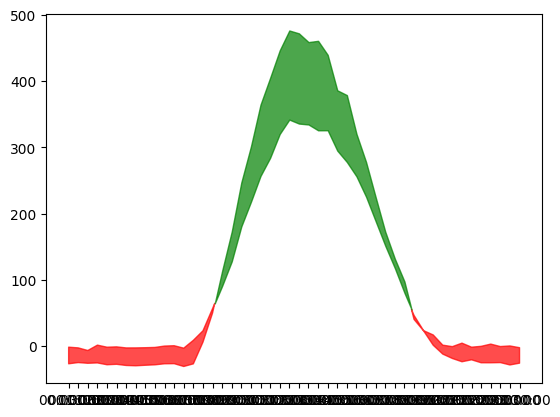

In [ ]:
#filling
plt.fill_between(data1['time'],data1['H+LE'], data1['Rn-G'],where = (data1['H+LE'] > data1['Rn-G']),alpha = 0.7,color = 'red',interpolate = True)
plt.fill_between(data1['time'],data1['H+LE'], data1['Rn-G'],where = (data1['H+LE'] <data1['Rn-G']),alpha = 0.7,color = 'green', interpolate = True)

### Author cell 4 — final formatted Figure 1 panel

**日本語:** 著者セル4のまま、軸ラベル・目盛り・凡例を整えた最終図を表示します。

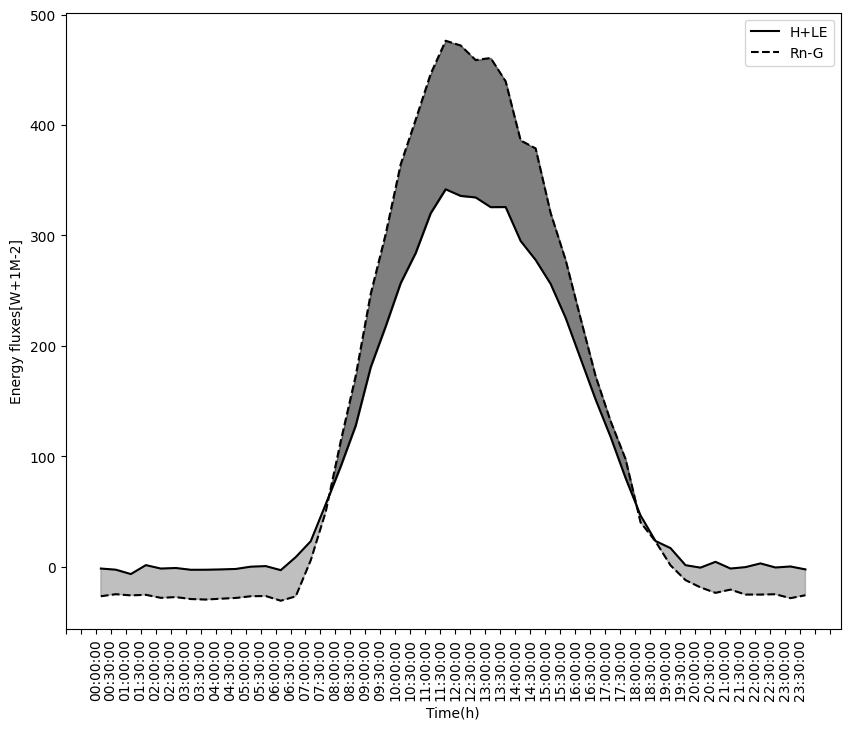

In [ ]:
#plotting and formatting
fig,ax = plt.subplots(1,1)
fig.set_size_inches(10,8)
#ax.plot(data1['time'],data1['H+LE'], data1['Rn-G'],lw=2)
ax.plot(data1['time'],data1['H+LE'], lw=1.5,color = 'black')
ax.plot(data1['time'], data1['Rn-G'],lw=1.5,linestyle='dashed',color = 'black')
plt.fill_between(data1['time'],data1['H+LE'], data1['Rn-G'],where = (data1['H+LE'] > data1['Rn-G']),alpha = 0.5,color = 'grey',interpolate = True)
plt.fill_between(data1['time'],data1['H+LE'], data1['Rn-G'],where = (data1['H+LE'] <data1['Rn-G']),alpha = 0.5,color = 'black', interpolate = True)
plt.xticks(rotation = 90)
start,end = ax.get_xlim()
ax.xaxis.set_ticks(np.arange(start,end,1))
ax.set(xlabel='Time(h)', ylabel='Energy fluxes[W+1M-2]');
plt.legend(['H+LE','Rn-G'])
plt.show()

## 6. The same composite for all eight averaging periods (extension)

**This panel set is an additional visualization created for this notebook**
(the paper shows the 30-min case in its Figure 1). It applies the authors'
plotting operations to every released `averaged_outputs/*.xlsx` diurnal
composite (1–120 min) so the effect of the averaging period on the diurnal
H+LE / Rn-G closure can be compared directly.

**日本語:** この8パネル図は本ノートブック用に追加した可視化です（論文のFigure 1は30分の場合）。著者の描画処理を全8区間の平均化済みファイルに適用し、平均化区間の違いを比較します。

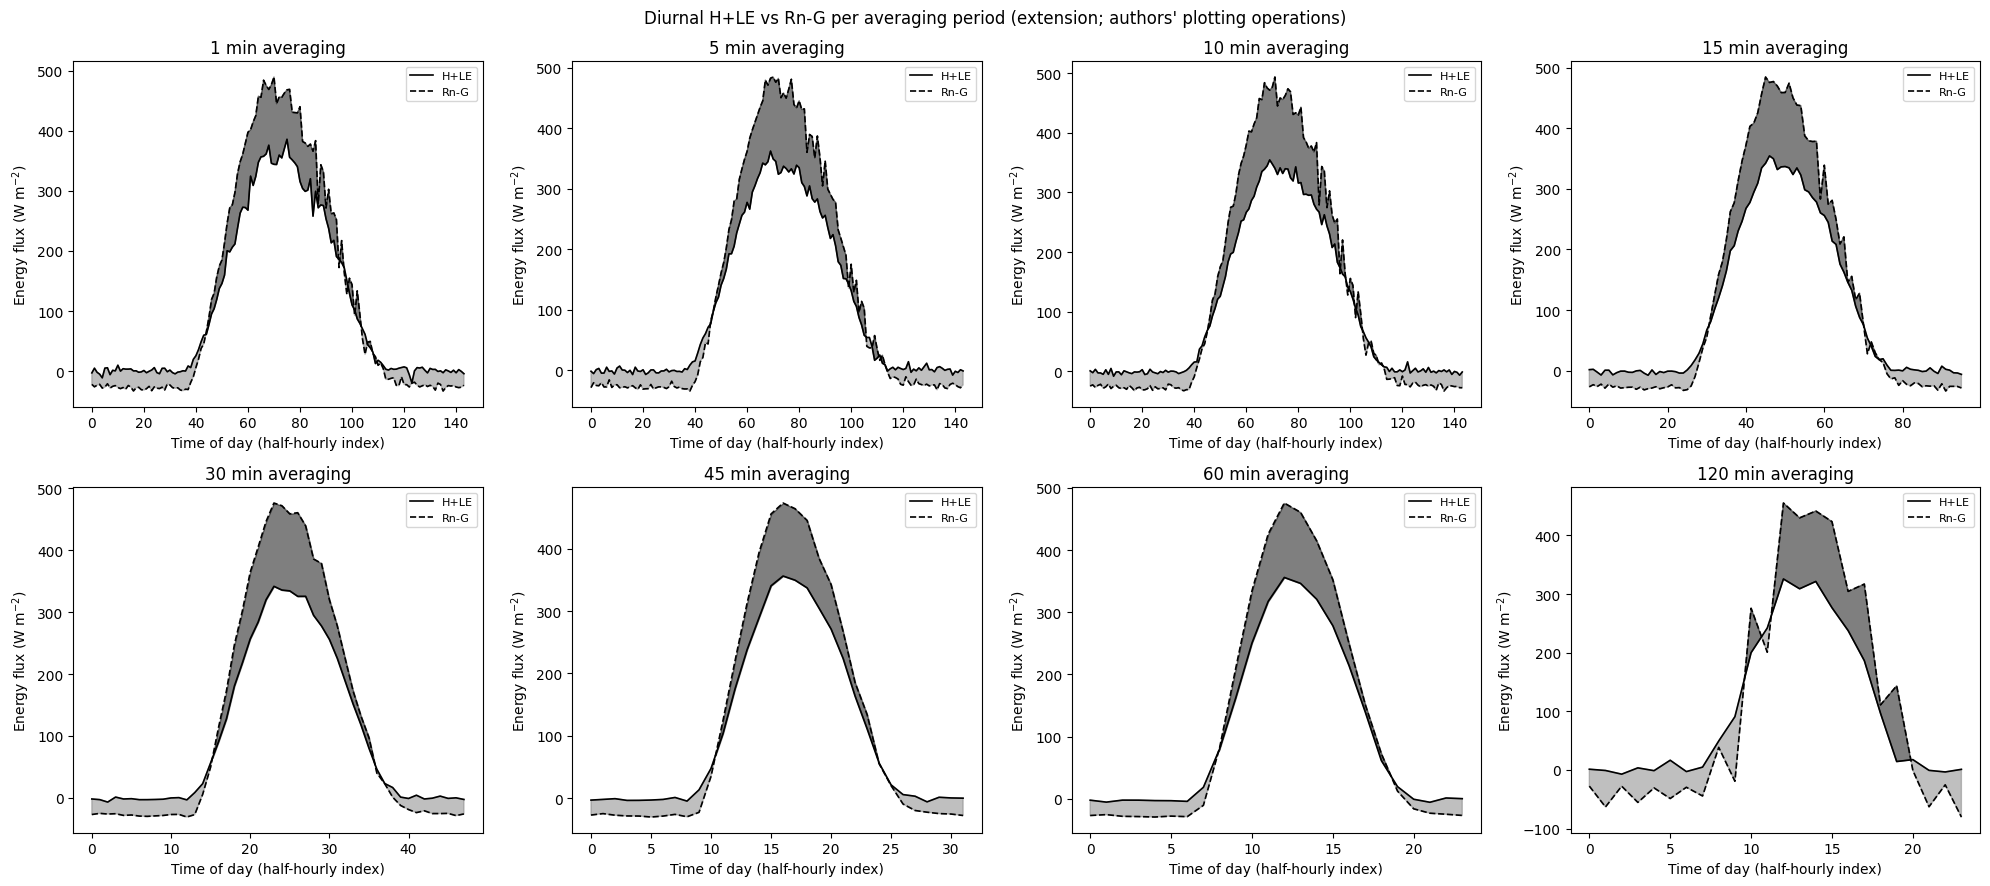

In [ ]:
periods = [("1 min", "1min_fig1_outputs1.xlsx"), ("5 min", "5min_fig1_outputs1.xlsx"),
           ("10 min", "10min_fig1_outputs1.xlsx"), ("15 min", "15min_fig1_outputs1.xlsx"),
           ("30 min", "30min_fig1_outputs1.xlsx"), ("45 min", "45min_fig1_outputs1.xlsx"),
           ("60 min", "60min_fig1_outputs1.xlsx"), ("120 min", "120min_fig1_outputs1.xlsx")]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (label, fname) in zip(axes.ravel(), periods):
    dfp = pd.read_excel(f'data/averaged_outputs/{fname}')
    x = np.arange(len(dfp))  # categorical time index (half-hourly rows)
    ax.plot(x, dfp['H+LE'], lw=1.2, color='black', label='H+LE')
    ax.plot(x, dfp['Rn-G'], lw=1.2, linestyle='dashed', color='black', label='Rn-G')
    ax.fill_between(x, dfp['H+LE'], dfp['Rn-G'], where=(dfp['H+LE'] > dfp['Rn-G']),
                    alpha=0.5, color='grey', interpolate=True)
    ax.fill_between(x, dfp['H+LE'], dfp['Rn-G'], where=(dfp['H+LE'] < dfp['Rn-G']),
                    alpha=0.5, color='black', interpolate=True)
    ax.set_title(f'{label} averaging')
    ax.set_xlabel('Time of day (half-hourly index)')
    ax.set_ylabel('Energy flux (W m$^{-2}$)')
    ax.legend(fontsize=8)
fig.suptitle("Diurnal H+LE vs Rn-G per averaging period (extension; authors' plotting operations)")
fig.tight_layout()
plt.show()

## 7. Table 2–analog: daily EBR and regression per averaging period

**This table is our own computation on the released data** (the paper's Table 2
uses the full corrected time series and quality filtering that are not part of
the release). Following the authors' aggregation cell
(`averaging_IWM-final1.ipynb`: `data.groupby(['Month','Day']).mean()`), each
`raw_file/*.xlsx` is reduced to daily means, then per period we report:
- **EBR** = Σ(H+LE)/Σ(Rn-G) over the season (ratio of daily totals),
- OLS **slope** and **intercept** of daily `H+LE` on daily `Rn-G`, with **R²**,
- **RMSE** of the daily `H+LE − (Rn-G)` difference (W m⁻²).

The paper's criteria for a good averaging period are slope ≥ 0.70 and
intercept ≤ 20 W m⁻² (Section 3.1); the paper reports the best closure at
45 and 60 min with slopes 0.59–0.71 and mean EBR ≈ 0.75.

**日本語:** 著者の`groupby(['Month','Day']).mean()`の日別集計に従い、各区間の生データから日平均値を求め、EBR（季節合計比）、H+LEのRn-Gへの回帰（傾き・切片・R²）、RMSEを計算します。論文は傾き≥0.70・切片≤20 W m⁻²を良好な閉合の基準とし、45分・60分が最良（傾き0.59–0.71、EBR≈0.75）と報告しています。

In [ ]:
rows = []
for label, _, raw_name in [
    ("1", "averaged_outputs/1min_fig1_outputs1.xlsx", "raw_file/1min figure1.xlsx"),
    ("5", "averaged_outputs/5min_fig1_outputs1.xlsx", "raw_file/5mins figure1_new.xlsx"),
    ("10", "averaged_outputs/10min_fig1_outputs1.xlsx", "raw_file/10min figure1.xlsx"),
    ("15", "averaged_outputs/15min_fig1_outputs1.xlsx", "raw_file/15min figure1.xlsx"),
    ("30", "averaged_outputs/30min_fig1_outputs1.xlsx", "raw_file/30min figure1.xlsx"),
    ("45", "averaged_outputs/45min_fig1_outputs1.xlsx", "raw_file/45min figure1.xlsx"),
    ("60", "averaged_outputs/60min_fig1_outputs1.xlsx", "raw_file/60min figure1.xlsx"),
    ("120", "averaged_outputs/120min_fig1_outputs1.xlsx", "raw_file/120min figure1.xlsx"),
]:
    dfr = pd.read_excel(f'data/{raw_name}')
    if 'Month' not in dfr.columns:  # compatibility adaptation: 5min file has datetime `date` only
        dt = pd.to_datetime(dfr['date'])
        dfr['Month'] = dt.dt.month
        dfr['Day'] = dt.dt.day
    daily = dfr.groupby(['Month', 'Day']).mean(numeric_only=True)  # authors' aggregation
    hle = daily['H+LE']
    rn_g = daily['Rn-G']
    slope, intercept = np.polyfit(rn_g, hle, 1)
    r2 = float(np.corrcoef(rn_g, hle)[0, 1] ** 2)
    rmse = float(np.sqrt(np.mean((hle - rn_g) ** 2)))
    rows.append({'period_min': int(label), 'EBR_season': float(hle.sum() / rn_g.sum()),
                 'slope': float(slope), 'intercept_Wm2': float(intercept),
                 'R2': r2, 'RMSE_Wm2': rmse, 'n_days': int(len(daily))})

results = pd.DataFrame(rows).set_index('period_min').sort_index()
results

,EBR_season,slope,intercept_Wm2,R2,RMSE_Wm2,n_days
period_min,,,,,,
1,0.879429,0.693435,22.955736,0.846128,20.696310,78
5,0.843475,0.692894,18.604927,0.859032,23.885470,78
10,0.833179,0.694336,17.239244,0.860802,24.955680,78
15,0.838708,0.695273,17.799684,0.854146,24.527942,78
30,0.827857,0.679489,18.556943,0.852391,25.917084,78
45,0.861503,0.713320,18.553739,0.806586,23.138614,78
60,0.857852,0.703492,19.452811,0.823965,23.478772,78
120,0.843039,0.672634,20.833867,0.700182,27.040253,72


## 8. Ranking against the paper's closure criteria

Periods are ranked by regression slope (higher is better) and compared with
the paper's criteria (slope ≥ 0.70, intercept ≤ 20 W m⁻²); the paper's reported
best periods (45 and 60 min) are marked for qualitative comparison. The results
table is also exported to CSV inside the Colab VM
(`/content/ebr_by_averaging_period.csv`) for inspection or download.

**日本語:** 各区間を傾きで順位付けし、論文の基準（傾き≥0.70、切片≤20 W m⁻²）と照合します。論文が最良とする45分・60分も表示します。結果表はColab内の`/content/ebr_by_averaging_period.csv`に保存され、ダウンロードできます。

            slope  intercept_Wm2  EBR_season  meets_criteria
period_min                                                  
45          0.713         18.554       0.862            True
60          0.703         19.453       0.858            True
15          0.695         17.800       0.839           False
10          0.694         17.239       0.833           False
1           0.693         22.956       0.879           False
5           0.693         18.605       0.843           False
30          0.679         18.557       0.828           False
120         0.673         20.834       0.843           False

Paper (Section 3.1): best slope (>= 0.70) and intercept (<= 20 W m-2) at the 45 and 60 min periods;


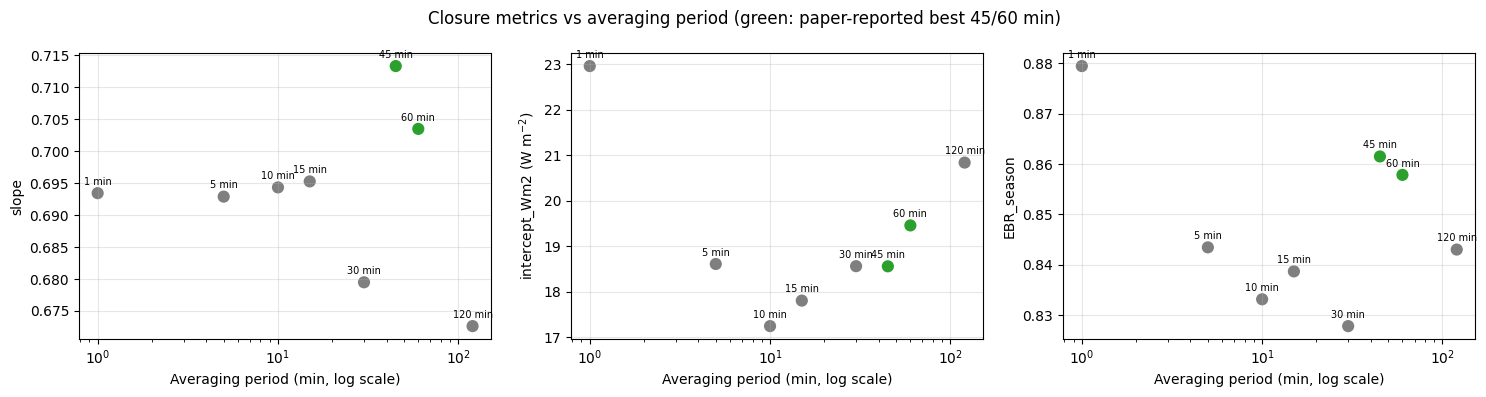

Saved /content/ebr_by_averaging_period.csv


In [ ]:
ranked = results.sort_values('slope', ascending=False)
ranked['meets_criteria'] = (ranked['slope'] >= 0.70) & (ranked['intercept_Wm2'] <= 20.0)
print(ranked[['slope', 'intercept_Wm2', 'EBR_season', 'meets_criteria']].round(3))
print("\nPaper (Section 3.1): best slope (>= 0.70) and intercept (<= 20 W m-2) at the 45 and 60 min periods;")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, unit in zip(axes, ['slope', 'intercept_Wm2', 'EBR_season'],
                         ['', ' (W m$^{-2}$)', '']):
    axes[0] if col == 'slope' else None
    marker = ['o' if p in (45, 60) else 's' for p in results.index]
    colors = ['tab:green' if p in (45, 60) else 'tab:gray' for p in results.index]
    ax.scatter(results.index, results[col], c=colors, s=60)
    for p in results.index:
        ax.annotate(f'{p} min', (p, results.loc[p, col]), fontsize=7,
                    xytext=(0, 6), textcoords='offset points', ha='center')
    ax.set_xscale('log')
    ax.set_xlabel('Averaging period (min, log scale)')
    ax.set_ylabel(f'{col}{unit}')
    ax.grid(alpha=0.3)
fig.suptitle('Closure metrics vs averaging period (green: paper-reported best 45/60 min)')
fig.tight_layout()
plt.show()

results.to_csv('/content/ebr_by_averaging_period.csv')
print('Saved /content/ebr_by_averaging_period.csv')

## 9. Interpretation, limitations, and references

**Interpretation.** The verbatim author cells reproduce the paper's Figure 1–
style diurnal composite: `H+LE` tracks `Rn-G` through the day with a marked
midday energy-balance deficit (turbulent energy below available energy). The
computed closure metrics show how the averaging period changes the daily
H+LE / Rn-G relationship; per the paper, 45 and 60 min averaging achieve the
best closure (slope ≥ 0.70, intercept ≤ 20 W m⁻², mean EBR ≈ 0.75), which the
ranking above compares qualitatively. Note that our metrics are computed on
the released per-period tables, **not** the paper's full corrected/quality-
filtered time series, so differences from the published Table 2 values are
expected; this run demonstrates the released analysis path, not dataset-level
paper accuracy.

**Limitations.** No raw 10 Hz data or EddyPro processing is included; the
repository dates to 2022 and its match to the final 2024 manuscript data is
unverified; no license file exists (Zenodo: `other-open`); the ogive (Fig. 5)
and WUE (Figs. 6–8) analyses are out of scope. Single-site, single-season
data — results do not generalize beyond this maize field case.

**日本語:** 著者コードのままFigure 1相当の日内変化図を再現し、平均化区間ごとの閉合指標を比較しました。本実行は公開データに基づく解析経路の再現であり、論文のTable 2の数値そのものとの一致は想定していません（品質管理や補正の詳細は非公開のため）。10 Hz生データ処理・オジャイブ解析・WUE解析は対象外です。単一サイト・単一季節のデータであり、一般化には注意してください。

**References.**
- Karimindla et al. (2024), AMT 17, 5477–5490, DOI 10.5194/amt-17-5477-2024 (preprint 10.5194/amt-2023-253).
- Author repository `Shweta07081992/Effect-of-averaging-period-of-eddy-covariance-fluxes-on-water-use-efficiency-` @ `28030cb1d8110d9bf907d1ef031bb6b3470af1cf` (`iwm_fig1_final1.ipynb`, `averaging_IWM-final1.ipynb`).
- Data: Zenodo DOI 10.5281/zenodo.7018282 (release v1.0.0).
- Paper study flow (PhenoPaper investigation `p-74406c771fce81281ee1993df6ca70be-20261028T084026Z-3641513`) used as research guidance, not primary proof.